目的/Objective
* LSTMを用いて時系列データから将来の大気汚染PM2.5を予測
* PyTorchで構築
---
* Predicting future air pollution PM2.5 using LSTM on time series data
* Built with PyTorch

インドの大気質データ (Air Quality Data in India 2017–2022)

**主な特徴量（説明変数）**

日付・時刻（Date/Time） – 観測日時

PM2.5（微小粒子状物質） – 空気の質の重要指標

PM10 – 粒子状物質10µm以下

NO2（二酸化窒素）SO2（二酸化硫黄）CO（一酸化炭素）O3（オゾン）気象データ（温度・湿度・風速など）

---

Air quality data of India (Air quality data in India 2017–2022)

**Key features (explanatory variables)**

Date/Time – Observation date and time

PM2.5 (Particulate matter) – An important indicator of air quality

PM10 – Particles smaller than 10 micrometers

NO2 (Nitrogen Dioxide), SO2 (Sulfur Dioxide), CO (Carbon Monoxide), O3 (Ozone), Meteorological data (Temperature, Humidity, Wind Speed, etc.)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Deep learning/lstm/

Mounted at /content/drive
/content/drive/MyDrive/Deep learning/lstm


In [ ]:
# Import
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

try:
    rcParams['font.family'] = 'WenQuanYi Zen Hei'
except Exception:
    pass

# 再現性/Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

plt.style.use('seaborn-v0_8')


Device: cuda


##### 1. データ読み込みと前処理/Load Data & Preprocess
* 時刻列 'Timestamp' を日時型に変換し、ソートして 1時間間隔へリサンプリング / Parse 'Timestamp', sort, and resample to hourly.  
* 欠損は線形補間で補完 / Fill missing values by linear interpolation.  
* ここでは PM2.5 のみを単変量系列として使用 / We use PM2.5 as a univariate series.

/tmp/ipython-input-1598835057.py:20: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  series = series.resample('1H').mean().interpolate('time')


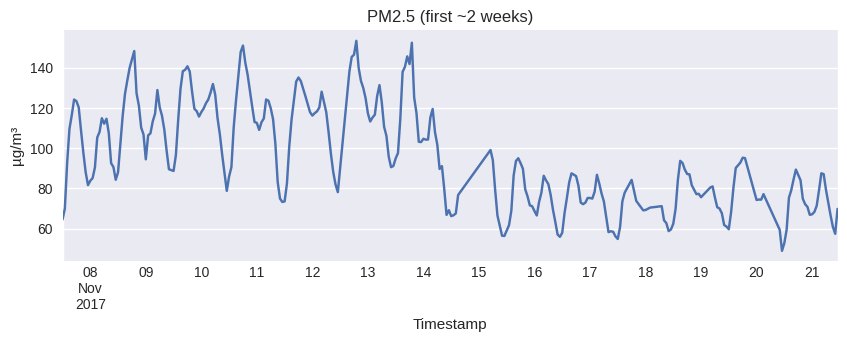

                      PM2.5
Timestamp                  
2017-11-07 12:00:00   64.51
2017-11-07 13:00:00   69.95
2017-11-07 14:00:00   92.79
2017-11-07 15:00:00  109.66
2017-11-07 16:00:00  116.50
                     PM2.5
Timestamp                 
2022-06-04 11:00:00  35.89
2022-06-04 12:00:00  33.83
2022-06-04 13:00:00  33.05
2022-06-04 14:00:00  35.29
2022-06-04 15:00:00  40.67


In [ ]:
# CSV読み込み / Read CSV
csv_path = '/content/drive/MyDrive/Deep learning/lstm/air-quality-india.csv'
df = pd.read_csv(csv_path)

# Timestamp を datetime へ / parse datetime
if 'Timestamp' in df.columns:
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])
else:
    df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0])
    df = df.rename(columns={df.columns[0]: 'Timestamp'})

# 必要列のみ / keep only timestamp & PM2.5
if 'PM2.5' not in df.columns:
    raise ValueError('PM2.5 column not found in CSV.')

series = df[['Timestamp','PM2.5']].dropna().sort_values('Timestamp')
series = series.set_index('Timestamp')

# Resample hourly & interpolate
series = series.resample('1H').mean().interpolate('time')

ax = series['PM2.5'].iloc[:24*14].plot(figsize=(10,3), title='PM2.5 (first ~2 weeks)')
ax.set_ylabel('µg/m³')
plt.show()

print(series.head())
print(series.tail())


##### 2. 正規化とシーケンス作成 / Scaling & Sequence Creation
* 値域0–1へMinMaxスケーリング / MinMax scale to [0,1].  
* look_back=24（過去24時間→次の1時間を予測）/ look_back=24 (last 24 hours → next hour).

In [ ]:
values = series[['PM2.5']].values.astype('float32')
scaler = MinMaxScaler()
scaled = scaler.fit_transform(values)

LOOK_BACK = 24

def make_sequences(arr, look_back=24):
    X, y = [], []
    for i in range(len(arr) - look_back):
        X.append(arr[i:i+look_back])
        y.append(arr[i+look_back])
    X = np.array(X)
    y = np.array(y)
    return X, y

X_all, y_all = make_sequences(scaled, LOOK_BACK)
print('X_all shape:', X_all.shape, 'y_all shape:', y_all.shape)


X_all shape: (40060, 24, 1) y_all shape: (40060, 1)


##### 3. 時系列分割（学習/検証/テスト）/ Time-based Split (Train/Val/Test)
* 順序を保って 70% / 15% / 15% に分割します。/ Split chronologically into 70% / 15% / 15%.

In [ ]:
N = len(X_all)
train_end = int(N * 0.7)
val_end = int(N * 0.85)

X_train, y_train = X_all[:train_end], y_all[:train_end]
X_val, y_val = X_all[train_end:val_end], y_all[train_end:val_end]
X_test, y_test = X_all[val_end:], y_all[val_end:]

print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)


Train: (28042, 24, 1) Val: (6009, 24, 1) Test: (6009, 24, 1)


##### 4. PyTorchデータセットとローダー / PyTorch Dataset & DataLoader
* (N, look_back, 1) を**テンソル化**して LSTM へ供給します。/ Convert to **tensors** for LSTM.
* torch.tensor: 数値のかたまりを、PyTorchが計算しやすい形にしたもの / A collection of numbers converted into a form that PyTorch can easily compute with.

In [ ]:
from torch.utils.data import Dataset, DataLoader

class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = SeqDataset(X_train, y_train)
val_ds = SeqDataset(X_val, y_val)
test_ds = SeqDataset(X_test, y_test)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)


##### 5. LSTMモデル定義 / Define LSTM Model (PyTorch)
* 入力1次元（PM2.5）/ input_size=1  
* 2層LSTM・隠れ64 / 2 LSTM layers with hidden size 64  
* ドロップアウト0.2 / dropout 0.2

In [ ]:
import torch
from torch import nn

class LSTMRegressor(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        last = out[:, -1, :]
        return self.fc(last)

model = LSTMRegressor().to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

sum(p.numel() for p in model.parameters())


50497

##### 6. 学習（早期終了付き）/ Training with Early Stopping
* エポックごとに学習損失・検証損失を記録します。/ Track train/val loss per epoch and stop early when validation stalls.

Epoch 01 | Train 0.007143 | Val 0.030030
Epoch 02 | Train 0.004420 | Val 0.030930
Epoch 03 | Train 0.004091 | Val 0.030242
Epoch 04 | Train 0.003536 | Val 0.017560
Epoch 05 | Train 0.002735 | Val 0.013369
Epoch 06 | Train 0.002223 | Val 0.010373
Epoch 07 | Train 0.001738 | Val 0.007950
Epoch 08 | Train 0.001399 | Val 0.006200
Epoch 09 | Train 0.001148 | Val 0.005165
Epoch 10 | Train 0.000952 | Val 0.004321
Epoch 11 | Train 0.000832 | Val 0.003715
Epoch 12 | Train 0.000738 | Val 0.003394
Epoch 13 | Train 0.000687 | Val 0.003089
Epoch 14 | Train 0.000657 | Val 0.002778
Epoch 15 | Train 0.000612 | Val 0.002511
Epoch 16 | Train 0.000587 | Val 0.002162
Epoch 17 | Train 0.000579 | Val 0.001985
Epoch 18 | Train 0.000565 | Val 0.001713
Epoch 19 | Train 0.000526 | Val 0.001543
Epoch 20 | Train 0.000503 | Val 0.001566
Epoch 21 | Train 0.000514 | Val 0.001447
Epoch 22 | Train 0.000493 | Val 0.001418
Epoch 23 | Train 0.000481 | Val 0.001487
Epoch 24 | Train 0.000466 | Val 0.001325
Epoch 25 | Train

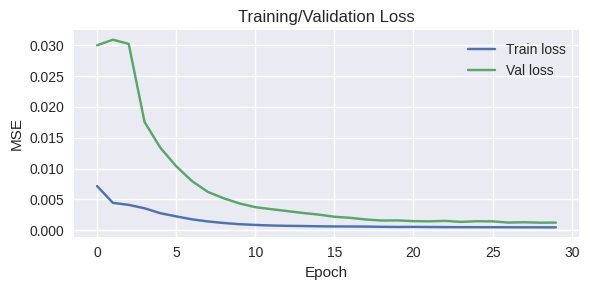

In [ ]:
EPOCHS = 30
PATIENCE = 5
best_val = float('inf')
wait = 0

train_losses, val_losses = [], []

for epoch in range(1, EPOCHS+1):
    model.train()
    epoch_train_loss = 0.0
    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        epoch_train_loss += loss.item() * xb.size(0)
    epoch_train_loss /= len(train_loader.dataset)

    model.eval()
    epoch_val_loss = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            pred = model(xb)
            loss = criterion(pred, yb)
            epoch_val_loss += loss.item() * xb.size(0)
    epoch_val_loss /= len(val_loader.dataset)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    print(f'Epoch {epoch:02d} | Train {epoch_train_loss:.6f} | Val {epoch_val_loss:.6f}')

    if epoch_val_loss < best_val - 1e-6:
        best_val = epoch_val_loss
        wait = 0
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE:
            print('Early stopping.')
            break

model.load_state_dict(best_state)

plt.figure(figsize=(6,3))
plt.plot(train_losses, label='Train loss')
plt.plot(val_losses, label='Val loss')
plt.title('Training/Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.show()


##### 7. 予測と可視化 / Inference & Visualization
* テスト区間で予測し、逆スケーリングで µg/m³ に戻します。全期間に対し、Train/Val の実測と Test 予測を同一図に描画します。

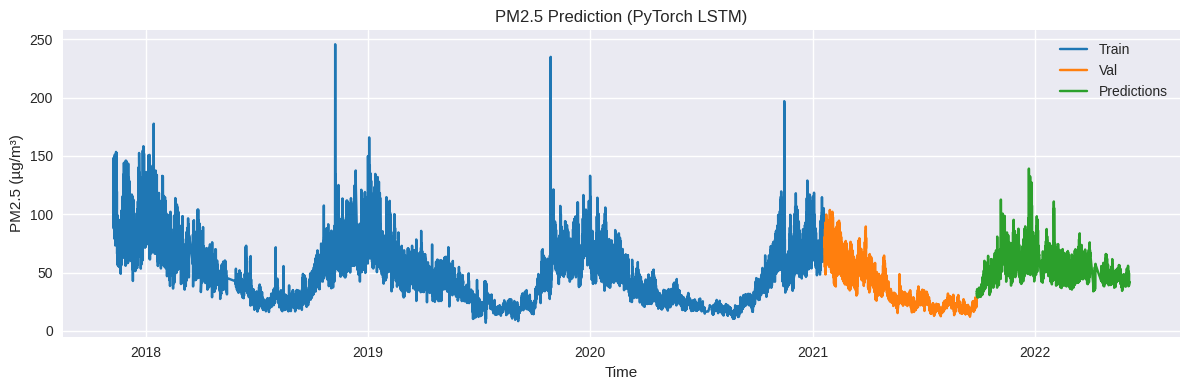

Test RMSE: 4.978 µg/m³ | Test MAE: 3.834 µg/m³


In [ ]:
model.eval()

# Collect predictions on test
import numpy as np
with torch.no_grad():
    test_preds = []
    for xb, _ in test_loader:
        xb = xb.to(DEVICE)
        pred = model(xb).cpu().numpy()
        test_preds.append(pred)
    test_preds = np.vstack(test_preds)

# Inverse-scale
inv_y_test = scaler.inverse_transform(y_test)
inv_y_pred = scaler.inverse_transform(test_preds)

full_index = series.index[LOOK_BACK:]
train_idx = full_index[:len(y_train)]
val_idx   = full_index[len(y_train): len(y_train)+len(y_val)]
test_idx  = full_index[len(y_train)+len(y_val):]

inv_y_all = scaler.inverse_transform(y_all)
inv_train = inv_y_all[:len(y_train), 0]
inv_val   = inv_y_all[len(y_train): len(y_train)+len(y_val), 0]

plt.figure(figsize=(12,4))
plt.plot(train_idx, inv_train, color='#1f77b4')
plt.plot(val_idx,   inv_val,   color='#ff7f0e')
plt.plot(test_idx,  inv_y_pred[:,0], color='#2ca02c')
plt.title('PM2.5 Prediction (PyTorch LSTM)')
plt.xlabel('Time')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend(['Train','Val','Predictions'])
plt.tight_layout()
plt.show()

rmse = math.sqrt(mean_squared_error(inv_y_test, inv_y_pred))
mae  = mean_absolute_error(inv_y_test, inv_y_pred)
print(f'Test RMSE: {rmse:.3f} µg/m³ | Test MAE: {mae:.3f} µg/m³')


##### 8. メモと拡張 / Notes & Extensions
* look_back を 24→48/72 に増やすと短期精度が改善する場合があります。/ Increasing look_back (e.g., 48 or 72) can help.  
* 多変量に拡張する場合は列を増やし、モデルの input_size を変更してください。/ For multivariate, add columns and adjust input_size.